PathSnap six-feature logistic regression

This notebook follows the supplied split protocol: 80 training trips are used for fitting and fixed five-fold trip-level cross-validation. The 10 student-test trips are evaluated once after cross-validation. Evaluator-test data is not loaded. Candidate rows from each trip stay in the same fold. The six preprocessed features and geometric weak labels are read from `PathSnap_shared6.zip`.

The labels are derived from the supplied reference routes, so the results measure agreement with those weak labels. The student-test partition is not used for hyperparameter selection.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/PathSnap_shared6.zip"
DATA_DIR = "/content/pathsnap_shared6"


Mounted at /content/drive


In [2]:
from pathlib import Path
from zipfile import ZipFile
import time
import json
import numpy as np
import pandas as pd

archive_path = Path(ZIP_PATH)
if not archive_path.exists():
    raise FileNotFoundError(f"Could not find {archive_path}. Update ZIP_PATH to the archive's Drive location.")

Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
files_to_extract = [
    "train_features.npz", "train_candidates.csv.gz", "train_observations.csv.gz",
    "student_test_features.npz", "student_test_candidates.csv.gz",
    "student_test_observations.csv.gz", "fold_assignments.csv", "feature_schema.json",
    "shared_protocol.json",
]

with ZipFile(archive_path) as archive:
    archive_files = set(archive.namelist())
    missing_files = sorted(set(files_to_extract) - archive_files)
    if missing_files:
        raise ValueError(f"Archive is missing required files: {missing_files}")
    for file_name in files_to_extract:
        archive.extract(file_name, DATA_DIR)

print("Loaded the preprocessed data files into", DATA_DIR)


Loaded the preprocessed data files into /content/pathsnap_shared6


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix,
)

DATA_PATH = Path(DATA_DIR)
FEATURES = [
    "distance_m", "distance_rank", "heading_difference_deg",
    "projection_fraction", "segment_length_m", "displacement_m",
]

with open(DATA_PATH / "feature_schema.json") as schema_file:
    feature_schema = json.load(schema_file)
assert [feature["name"] for feature in feature_schema] == FEATURES

with np.load(DATA_PATH / "train_features.npz", allow_pickle=False) as data:
    train_features = data["X"].astype(np.float64)
    train_labels = data["label"].astype(np.int8)
    train_trip_ids = data["trip_id"].astype(str)

with np.load(DATA_PATH / "student_test_features.npz", allow_pickle=False) as data:
    student_features = data["X"].astype(np.float64)
    student_labels = data["label"].astype(np.int8)
    student_trip_ids = data["trip_id"].astype(str)

train_candidates = pd.read_csv(DATA_PATH / "train_candidates.csv.gz", dtype={"trip_id": str})
student_candidates = pd.read_csv(DATA_PATH / "student_test_candidates.csv.gz", dtype={"trip_id": str})
train_observations = pd.read_csv(DATA_PATH / "train_observations.csv.gz", dtype={"trip_id": str})
student_observations = pd.read_csv(DATA_PATH / "student_test_observations.csv.gz", dtype={"trip_id": str})
fold_assignments = pd.read_csv(DATA_PATH / "fold_assignments.csv", dtype={"trip_id": str})

assert train_features.shape == (len(train_candidates), len(FEATURES))
assert len(train_labels) == len(train_candidates)
assert student_features.shape == (len(student_candidates), len(FEATURES))
assert len(student_labels) == len(student_candidates)
assert np.isfinite(train_features).all() and np.isfinite(student_features).all()
assert np.array_equal(train_trip_ids, train_candidates.trip_id.to_numpy())
assert np.array_equal(student_trip_ids, student_candidates.trip_id.to_numpy())
assert set(fold_assignments.trip_id) == set(train_trip_ids)

print(f"Training set: {len(set(train_trip_ids))} trips, {len(train_features):,} candidate rows")
print(f"Student-test set: {len(set(student_trip_ids))} trips, {len(student_features):,} candidate rows")
print("Features:", FEATURES)
print("Positive-label share in training candidates:", round(float(train_labels.mean()), 5))


Training set: 80 trips, 1,241,756 candidate rows
Student-test set: 10 trips, 125,525 candidate rows
Features: ['distance_m', 'distance_rank', 'heading_difference_deg', 'projection_fraction', 'segment_length_m', 'displacement_m']
Positive-label share in training candidates: 0.14926


Exploratory plots below use the 80 training trips only. They summarize trip lengths, weak candidate labels, and the six preprocessed features before model fitting.

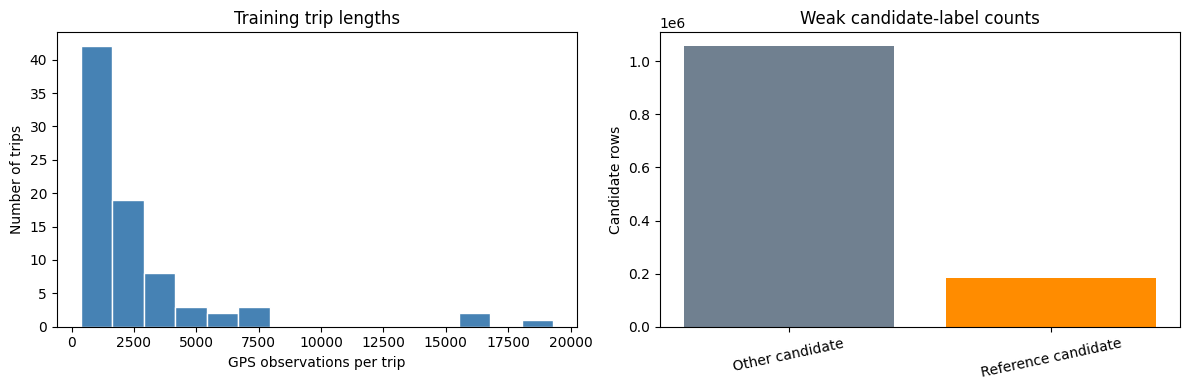

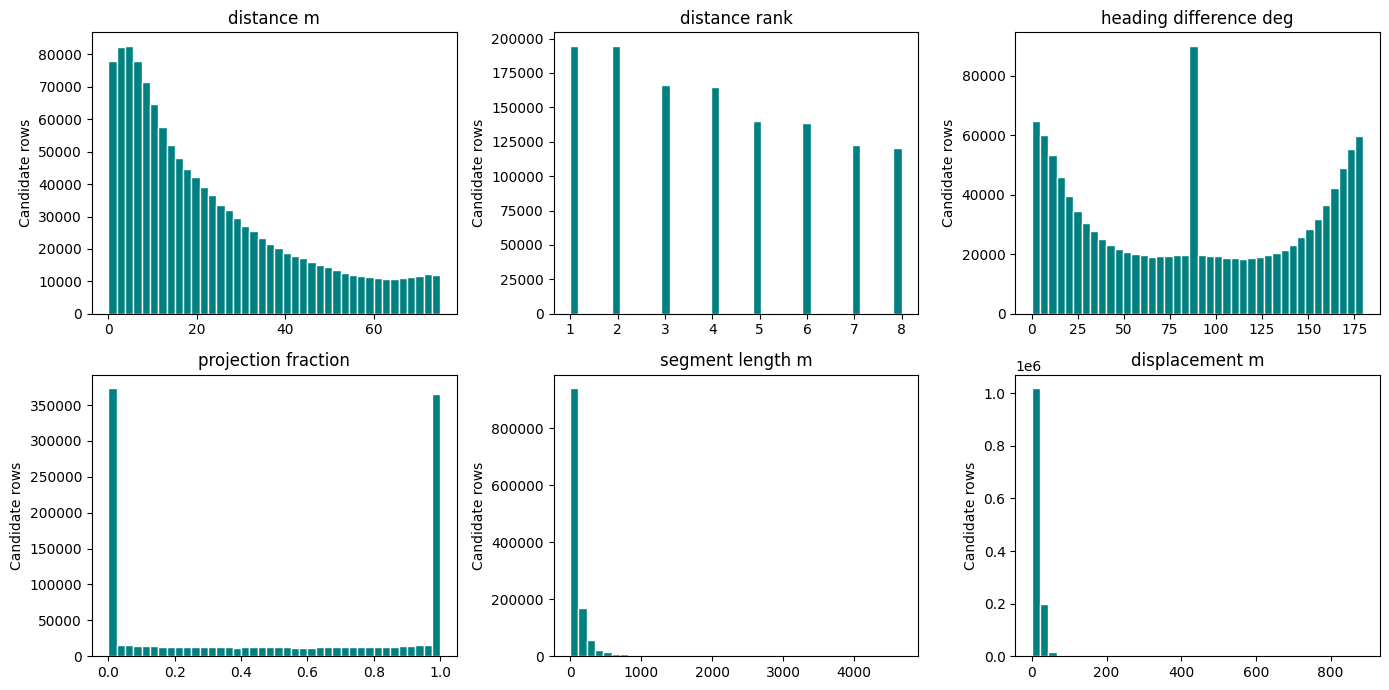

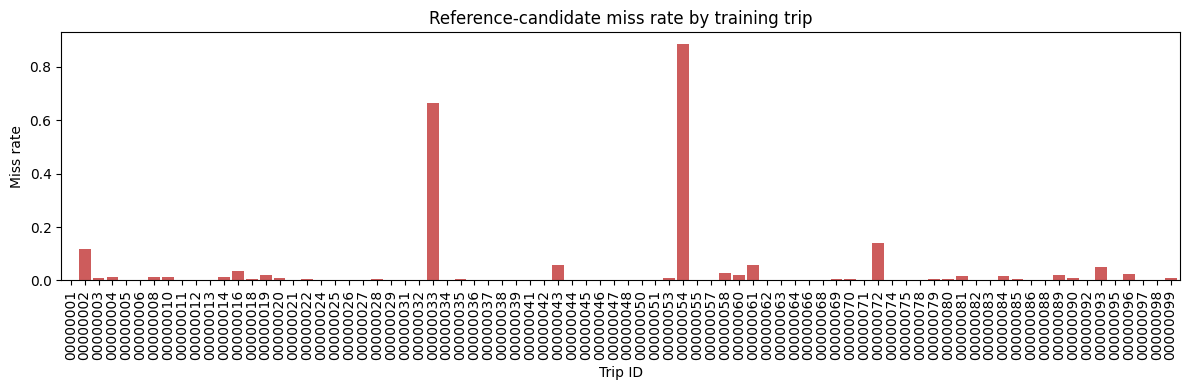

In [4]:
import matplotlib.pyplot as plt

trip_lengths = train_observations.groupby("trip_id").size()
positive_counts = np.bincount(train_labels, minlength=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(trip_lengths, bins=15, color="steelblue", edgecolor="white")
axes[0].set_title("Training trip lengths")
axes[0].set_xlabel("GPS observations per trip")
axes[0].set_ylabel("Number of trips")

axes[1].bar(["Other candidate", "Reference candidate"], positive_counts,
            color=["slategray", "darkorange"])
axes[1].set_title("Weak candidate-label counts")
axes[1].set_ylabel("Candidate rows")
axes[1].tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for axis, feature_name in zip(axes.flat, FEATURES):
    axis.hist(train_candidates[feature_name], bins=40, color="teal", edgecolor="white")
    axis.set_title(feature_name.replace("_", " "))
    axis.set_ylabel("Candidate rows")
plt.tight_layout()
plt.show()

miss_rate_by_trip = 1 - train_observations.groupby("trip_id").reference_present.mean()
plt.figure(figsize=(12, 4))
miss_rate_by_trip.sort_index().plot(kind="bar", color="indianred", width=0.85)
plt.title("Reference-candidate miss rate by training trip")
plt.xlabel("Trip ID")
plt.ylabel("Miss rate")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


This interactive map shows a representative training trip's GPS observations and their chronological GPS trace. Marker color indicates whether the reference road arc was present in the generated candidate set. The six-feature archive contains no road-segment endpoint geometry, so this map cannot draw the road network or the reference road route.

Evaluation details

Binary classification metrics use a fixed probability threshold of 0.5. For observation-level top-1 accuracy, the candidate with the highest predicted probability is selected; ties follow the archive's distance-rank and arc-ID order. Candidate miss rate is the share of observations whose reference arc is missing from the generated candidates. Mean trip top-1 accuracy averages the pointwise accuracy within each trip. Exact sequence accuracy counts a trip as correct only when every observation is correct. The confusion matrix uses label order `[0, 1].

In [5]:
def evaluate_partition(labels, candidate_rows, observation_rows, probabilities,
                        training_seconds=0.0, inference_seconds=0.0):
    probabilities = np.asarray(probabilities, dtype=float)
    assert probabilities.shape == (len(candidate_rows),)
    assert np.isfinite(probabilities).all()

    predicted_labels = (probabilities >= 0.5).astype(np.int8)
    metrics = {
        "Accuracy": accuracy_score(labels, predicted_labels),
        "Precision (positive class)": precision_score(labels, predicted_labels, zero_division=0),
        "Recall (positive class)": recall_score(labels, predicted_labels, zero_division=0),
        "F1 (positive class)": f1_score(labels, predicted_labels, zero_division=0),
        "Macro F1": f1_score(labels, predicted_labels, average="macro", labels=[0, 1], zero_division=0),
        "Log Loss": log_loss(labels, np.column_stack([1 - probabilities, probabilities]), labels=[0, 1]),
        "Training Time (s)": training_seconds,
        "Inference Time (s)": inference_seconds,
    }

    ranked_candidates = candidate_rows[["trip_id", "observation_id", "arc_id", "distance_rank"]].copy()
    ranked_candidates["probability"] = probabilities
    best_candidate_per_observation = (
        ranked_candidates.sort_values(
            ["observation_id", "probability", "distance_rank", "arc_id"],
            ascending=[True, False, True, True], kind="stable",
        )
        .drop_duplicates("observation_id")
    )
    observation_results = observation_rows.copy().merge(
        best_candidate_per_observation[["observation_id", "arc_id"]],
        on="observation_id", how="left", validate="one_to_one",
    )
    observation_results["top1_correct"] = (
        observation_results["arc_id"] == observation_results["reference_arc_id"]
    )

    metrics["Observation-level Top-1 Accuracy"] = float(observation_results.top1_correct.mean())
    reference_is_covered = observation_results.reference_present.astype(bool)
    metrics["Candidate Miss Rate"] = float((~reference_is_covered).mean())
    metrics["Top-1 Accuracy (covered observations)"] = (
        float(observation_results.loc[reference_is_covered, "top1_correct"].mean())
        if reference_is_covered.any() else np.nan
    )

    confusion = confusion_matrix(labels, predicted_labels, labels=[0, 1])
    trip_scores = observation_results.groupby("trip_id", sort=True).top1_correct.agg(["mean", "all"])
    metrics["Mean Trip Top-1 Accuracy"] = float(trip_scores["mean"].mean())
    metrics["Exact Sequence Accuracy"] = float(trip_scores["all"].mean())
    metrics["Route Continuity"] = np.nan
    return metrics, confusion, observation_results


def make_logistic_regression():
    return LogisticRegression(
        solver="lbfgs", C=1.0, max_iter=1000,
        class_weight=None, random_state=42,
    )


Five-fold trip-level cross-validation

The archive's fixed fold assignments are used as provided. The scaler for each fold is fitted only on the other four folds, then applied to that fold's held-out trips. This keeps observations from one trip together and prevents validation data from affecting scaling.

In [6]:
fold_results = []
fold_confusion_matrices = {}

for fold_number in range(1, 6):
    validation_trips = set(
        fold_assignments.loc[fold_assignments.fold == fold_number, "trip_id"]
    )
    is_validation_row = np.isin(train_trip_ids, list(validation_trips))
    training_indices = np.flatnonzero(~is_validation_row)
    validation_indices = np.flatnonzero(is_validation_row)

    assert set(train_trip_ids[training_indices]).isdisjoint(
        set(train_trip_ids[validation_indices])
    )

    fold_scaler = StandardScaler().fit(train_features[training_indices])
    fold_train_features = fold_scaler.transform(train_features[training_indices])
    fold_validation_features = fold_scaler.transform(train_features[validation_indices])
    model = make_logistic_regression()

    timer_start = time.perf_counter()
    model.fit(fold_train_features, train_labels[training_indices])
    training_seconds = time.perf_counter() - timer_start

    timer_start = time.perf_counter()
    validation_probabilities = model.predict_proba(fold_validation_features)[:, 1]
    inference_seconds = time.perf_counter() - timer_start

    validation_candidates = train_candidates.iloc[validation_indices].reset_index(drop=True)
    validation_observations = train_observations[
        train_observations.trip_id.isin(validation_trips)
    ].copy()
    fold_metrics, fold_confusion, _ = evaluate_partition(
        train_labels[validation_indices], validation_candidates,
        validation_observations, validation_probabilities,
        training_seconds, inference_seconds,
    )
    fold_results.append({
        "Fold": fold_number,
        "Validation Trips": len(validation_trips),
        **fold_metrics,
    })
    fold_confusion_matrices[fold_number] = fold_confusion

cross_validation_results = pd.DataFrame(fold_results).set_index("Fold")
display(cross_validation_results.round(4))
print("Fold metric averages and standard deviations")
display(pd.DataFrame({
    "Mean": cross_validation_results.mean(),
    "Standard deviation": cross_validation_results.std(ddof=1),
}).round(4))


,Validation Trips,Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),Macro F1,Log Loss,Training Time (s),Inference Time (s),Observation-level Top-1 Accuracy,Candidate Miss Rate,Top-1 Accuracy (covered observations),Mean Trip Top-1 Accuracy,Exact Sequence Accuracy,Route Continuity
Fold,,,,,,,,,,,,,,,
1,15,0.9259,0.7249,0.6804,0.7019,0.8298,0.1889,2.0321,0.0128,0.4487,0.4138,0.7653,0.7344,0.0,NaN
2,16,0.9144,0.7532,0.6696,0.7090,0.8294,0.2115,1.2868,0.0232,0.7486,0.0169,0.7614,0.7767,0.0,NaN
3,16,0.9037,0.7566,0.6803,0.7164,0.8292,0.2229,2.4744,0.0276,0.7581,0.0010,0.7588,0.8154,0.0,NaN
4,16,0.9385,0.7651,0.7800,0.7725,0.8685,0.1619,2.4056,0.0181,0.7768,0.0980,0.8612,0.8133,0.0,NaN
5,17,0.9293,0.7936,0.7064,0.7475,0.8532,0.1815,1.6538,0.0151,0.7716,0.0237,0.7903,0.7968,0.0,NaN


Fold metric averages and standard deviations


,Mean,Standard deviation
Validation Trips,16.0000,0.7071
Accuracy,0.9223,0.0135
Precision (positive class),0.7587,0.0247
Recall (positive class),0.7033,0.0449
F1 (positive class),0.7295,0.0297
Macro F1,0.8420,0.0180
Log Loss,0.1933,0.0242
Training Time (s),1.9705,0.5036
Inference Time (s),0.0194,0.0060
Observation-level Top-1 Accuracy,0.7007,0.1414


Fit on all training trips and evaluate the student-test set

After cross-validation, the fixed model is refitted using all 80 training trips. The scaler is fitted on training data only. The student-test trips are used for this final evaluation and are not used to choose model settings.

In [7]:
training_scaler = StandardScaler().fit(train_features)
scaled_train_features = training_scaler.transform(train_features)
scaled_student_features = training_scaler.transform(student_features)
logistic_model = make_logistic_regression()

timer_start = time.perf_counter()
logistic_model.fit(scaled_train_features, train_labels)
student_training_seconds = time.perf_counter() - timer_start

timer_start = time.perf_counter()
student_probabilities = logistic_model.predict_proba(scaled_student_features)[:, 1]
student_inference_seconds = time.perf_counter() - timer_start

student_metrics, student_confusion_matrix, student_point_predictions = evaluate_partition(
    student_labels, student_candidates, student_observations, student_probabilities,
    student_training_seconds, student_inference_seconds,
)


The following cell prints cross-validation results, student-test metrics, the confusion matrix, and the fitted model settings. Route continuity is unavailable because the shared feature archive does not contain road-network endpoint data.

In [8]:
print("5-fold cross-validation results")
display(cross_validation_results.round(4))

print("\nStudent-test metrics")
display(pd.Series(student_metrics, name="Value").to_frame().round(5))

print("\nStudent-test confusion matrix")
print("Rows are true labels [0, 1]; columns are predicted labels [0, 1].")
display(pd.DataFrame(
    student_confusion_matrix,
    index=["True 0", "True 1"],
    columns=["Predicted 0", "Predicted 1"],
))

print("\nLogistic regression settings")
print(logistic_model)
print("Features:", FEATURES)


5-fold cross-validation results


,Validation Trips,Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),Macro F1,Log Loss,Training Time (s),Inference Time (s),Observation-level Top-1 Accuracy,Candidate Miss Rate,Top-1 Accuracy (covered observations),Mean Trip Top-1 Accuracy,Exact Sequence Accuracy,Route Continuity
Fold,,,,,,,,,,,,,,,
1,15,0.9259,0.7249,0.6804,0.7019,0.8298,0.1889,2.0321,0.0128,0.4487,0.4138,0.7653,0.7344,0.0,NaN
2,16,0.9144,0.7532,0.6696,0.7090,0.8294,0.2115,1.2868,0.0232,0.7486,0.0169,0.7614,0.7767,0.0,NaN
3,16,0.9037,0.7566,0.6803,0.7164,0.8292,0.2229,2.4744,0.0276,0.7581,0.0010,0.7588,0.8154,0.0,NaN
4,16,0.9385,0.7651,0.7800,0.7725,0.8685,0.1619,2.4056,0.0181,0.7768,0.0980,0.8612,0.8133,0.0,NaN
5,17,0.9293,0.7936,0.7064,0.7475,0.8532,0.1815,1.6538,0.0151,0.7716,0.0237,0.7903,0.7968,0.0,NaN



Student-test metrics


,Value
Accuracy,0.93101
Precision (positive class),0.78809
Recall (positive class),0.74801
F1 (positive class),0.76753
Macro F1,0.86351
Log Loss,0.18000
Training Time (s),2.08508
Inference Time (s),0.00631
Observation-level Top-1 Accuracy,0.80966
Candidate Miss Rate,0.00251



Student-test confusion matrix
Rows are true labels [0, 1]; columns are predicted labels [0, 1].


,Predicted 0,Predicted 1
True 0,102569,3844
True 1,4816,14296



Logistic regression settings
LogisticRegression(max_iter=1000, random_state=42)
Features: ['distance_m', 'distance_rank', 'heading_difference_deg', 'projection_fraction', 'segment_length_m', 'displacement_m']


This interactive map uses a student-test trip. It uses an Esri World Imagery background to avoid the blocked OpenStreetMap tile service. If the original trip network files are available, the map adds candidate roads, supplied reference roads, and Logistic Regression-selected roads. Otherwise it displays the GPS trajectory only.

In [9]:
from pathlib import Path
import folium
from IPython.display import display

RAW_DATA_ROOT = Path("/content/drive/MyDrive/Student folder")
SHOW_BACKGROUND = True

map_trip_id = sorted(student_observations.trip_id.unique())[0]
trip_observations = (
    student_point_predictions.loc[student_point_predictions.trip_id == map_trip_id]
    .sort_values("timestamp")
    .copy()
)
trip_observations = trip_observations.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["latitude", "longitude"]
)
gps_coordinates = trip_observations[["latitude", "longitude"]].to_numpy().tolist()

if not gps_coordinates:
    print(f"No valid GPS coordinates for trip {map_trip_id}.")
else:
    tile_options = {
        "tiles": (
            "https://services.arcgisonline.com/ArcGIS/rest/services/"
            "World_Imagery/MapServer/tile/{z}/{y}/{x}"
        ) if SHOW_BACKGROUND else None,
        "attr": "Esri, Vantor, Earthstar Geographics, and the GIS User Community",
    } if SHOW_BACKGROUND else {"tiles": None}
    trip_map = folium.Map(
        location=[trip_observations.latitude.mean(), trip_observations.longitude.mean()],
        zoom_start=13,
        control_scale=True,
        **tile_options,
    )

    gps_layer = folium.FeatureGroup(name="Observed GPS", show=True)
    folium.PolyLine(
        gps_coordinates, color="red", weight=3,
        tooltip=f"Recorded GPS trajectory, trip {map_trip_id}",
    ).add_to(gps_layer)
    marker_step = max(1, len(trip_observations) // 300)
    for row in trip_observations.iloc[::marker_step].itertuples():
        folium.CircleMarker(
            location=[row.latitude, row.longitude], radius=2,
            color="red", fill=True, fill_opacity=0.8,
            popup=f"GPS observation {row.observation_id}",
        ).add_to(gps_layer)
    gps_layer.add_to(trip_map)

    trip_folder = RAW_DATA_ROOT / "student_test" / map_trip_id
    node_path = trip_folder / f"{map_trip_id}.nodes"
    arc_path = trip_folder / f"{map_trip_id}.arcs"
    route_path = trip_folder / f"{map_trip_id}.route"

    if node_path.is_file() and arc_path.is_file():
        nodes = np.loadtxt(node_path, ndmin=2)
        arcs = np.loadtxt(arc_path, dtype=int, ndmin=2)

        def add_road_segments(arc_ids, layer_name, color, weight, show=True):
            arc_ids = np.unique(np.asarray(arc_ids, dtype=int))
            if len(arc_ids) and (arc_ids.min() < 0 or arc_ids.max() >= len(arcs)):
                raise ValueError(f"{layer_name}: arc IDs are outside this trip's road network")
            layer = folium.FeatureGroup(name=layer_name, show=show)
            for arc_id in arc_ids:
                segment_coordinates = nodes[arcs[arc_id]][:, [1, 0]].tolist()
                folium.PolyLine(
                    segment_coordinates, color=color, weight=weight,
                    tooltip=f"Arc {arc_id}",
                ).add_to(layer)
            layer.add_to(trip_map)

        candidate_arc_ids = student_candidates.loc[
            student_candidates.trip_id == map_trip_id, "arc_id"
        ].to_numpy()
        add_road_segments(candidate_arc_ids, "Candidate roads", "gray", 1, show=False)

        if route_path.is_file():
            reference_arc_ids = np.loadtxt(route_path, dtype=int, ndmin=1)
            reference_layer_name = "Supplied reference route"
        else:
            reference_arc_ids = trip_observations.reference_arc_id.to_numpy()
            reference_layer_name = "Derived reference segments"
        add_road_segments(reference_arc_ids, reference_layer_name, "lime", 5)

        predicted_arc_ids = trip_observations.arc_id.dropna().astype(int).to_numpy()
        add_road_segments(predicted_arc_ids, "Logistic Regression selections", "cyan", 3)
        print("Map layers: red = GPS, gray = candidate roads, green = reference, cyan = model selections.")
    else:
        print("Showing GPS only. Set RAW_DATA_ROOT to the extracted original Student folder to add road layers.")
        print("Expected network files under:", trip_folder)

    trip_map.fit_bounds([
        [trip_observations.latitude.min(), trip_observations.longitude.min()],
        [trip_observations.latitude.max(), trip_observations.longitude.max()],
    ])
    folium.LayerControl().add_to(trip_map)
    display(trip_map)


Showing GPS only. Set RAW_DATA_ROOT to the extracted original Student folder to add road layers.
Expected network files under: /content/drive/MyDrive/Student folder/student_test/00000000
